In [86]:
#!/usr/bin/env python3
# --- Imports ---

import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt


In [87]:
working_dir = Path.cwd()
project_dir = working_dir.parent if working_dir.name == "notebooks" else working_dir
csv_path = project_dir / "results" / "fake_bench.csv"

df = pd.read_csv(csv_path)

print(f"DataFrame shape: {df.shape}")
print(f"DataFrame columns: {df.columns.tolist()}")

df.head()
df.info()
df.describe()

DataFrame shape: (84, 6)
DataFrame columns: ['config', 'run', 'prompt_tokens', 'generated_tokens', 'ttft_ms', 'latency_ms']
<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   config            84 non-null     str    
 1   run               84 non-null     int64  
 2   prompt_tokens     84 non-null     int64  
 3   generated_tokens  84 non-null     int64  
 4   ttft_ms           84 non-null     float64
 5   latency_ms        84 non-null     float64
dtypes: float64(2), int64(3), str(1)
memory usage: 4.1 KB


,run,prompt_tokens,generated_tokens,ttft_ms,latency_ms
count,84.000000,84.000000,84.000000,84.000000,84.000000
mean,10.000000,1312.500000,149.285714,1033.225000,9726.542857
std,6.091669,500.955412,163.824441,907.351636,9024.119563
min,0.000000,450.000000,38.000000,248.800000,2255.300000
25%,5.000000,1312.500000,54.000000,805.850000,4016.125000
50%,10.000000,1600.000000,63.500000,906.800000,5019.400000
75%,15.000000,1600.000000,119.000000,1152.375000,10208.700000
max,20.000000,1600.000000,566.000000,5201.300000,33151.200000


In [88]:
# Run 0 of each config is a warmup (includes model loading): excluded by protocol.
df_clean = df[df["run"] > 0].copy()

# Sanity check: how far is the warmup TTFT from the median of the real runs?
median_ttft = df_clean.groupby("config")["ttft_ms"].median()
warmup = df[df["run"] == 0].set_index("config")["ttft_ms"]
print((warmup / median_ttft).round(1).rename("warmup_vs_median"))

config
baseline                  5.7
no_think                  5.3
no_think_short_prompt    12.5
q8_no_think               3.9
Name: warmup_vs_median, dtype: float64


In [89]:
# Ajout de la colonne token_per_s pour calculer le nombre de tokens par seconde
df_clean['token_per_s'] = df_clean['generated_tokens'] / (df_clean['latency_ms'] / 1000)

In [90]:
# Ajout de la colonne decode_tokens_per_s pour calculer le nombre de tokens par seconde pendant la phase de décodage
df_clean["decode_tokens_per_s"] = df_clean["generated_tokens"] / (
    (df_clean["latency_ms"] - df_clean["ttft_ms"]) / 1000
)

In [91]:
# groupby("config") : mediane et 90e centile de la latence 

df_stats = df_clean.groupby("config").agg(
    median_ttft_ms=("ttft_ms", "median"),
    median_latency_ms=("latency_ms", "median"),
    median_token_per_s=("token_per_s", "median"),
    median_decode_tokens_per_s=("decode_tokens_per_s", "median"),
    p90_ttft_ms=("ttft_ms", lambda x: x.quantile(0.9)),
    p90_latency_ms=("latency_ms", lambda x: x.quantile(0.9)),
    p10_token_per_s=("token_per_s", lambda x: x.quantile(0.1)),
    p10_decode_tokens_per_s=("decode_tokens_per_s", lambda x: x.quantile(0.1)),
)

baseline = df_stats.loc["baseline" , "median_latency_ms"]

In [92]:
# trier de config la plus rapide à la plus lente en fonction de la latence médiane
df_stats = df_stats.sort_values(by=["median_latency_ms"] , ascending=True)
df_stats["gain_vs_baseline_pct"] = (baseline - df_stats["median_latency_ms"]) / baseline * 100
df_stats.head().to_markdown

<bound method DataFrame.to_markdown of                        median_ttft_ms  median_latency_ms  median_token_per_s  \
config                                                                         
no_think_short_prompt          298.85            3531.80           17.311165   
no_think                       897.60            4300.85           13.963994   
q8_no_think                   1293.55            5910.80            9.360170   
baseline                       910.05           24218.70           17.383126   

                       median_decode_tokens_per_s  p90_ttft_ms  \
config                                                           
no_think_short_prompt                   18.989401       327.18   
no_think                                17.666366       964.24   
q8_no_think                             11.677618      1432.38   
baseline                                18.087238       957.37   

                       p90_latency_ms  p10_token_per_s  \
config                   

ValueError: 'yerr' must not contain negative values

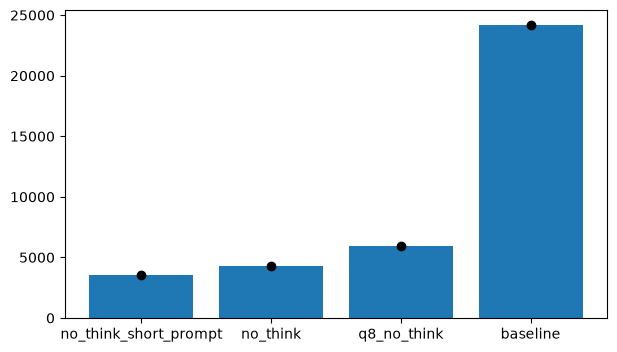

In [ ]:
# Création de graphiques pour visualiser mes données 

lat = df_clean.groupby("config")["latency_ms"]
summary = pd.DataFrame({
    "p10": lat.quantile(0.1),
    "median": lat.median(),
    "p90": lat.quantile(0.9)
}) / 1000  # Convert to seconds

summary.sort_values(by="median", inplace=True)

lower = summary["median"] - summary["p10"]
upper = summary["p90"] - summary["median"]

fig , ax = plt.subplots(figsize=(7,4))

#Ajouter les quantiles 90e et 10e pour la latence et le nombre de tokens par seconde
ax.bar(df_stats.index, df_stats["median_latency_ms"])


ax.set_xlabel("Configuration")
ax.set_ylabel("Median Latency (ms)")
ax.set_title("Median Latency by Configuration")

plt.show()